<a href="https://colab.research.google.com/github/miyagi-art/simulacion2/blob/main/derivados_del_MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ingresa el valor deseado para B_1: 5
Mu teórica: 1.5 | Mu estimada en simulación: 1.3572
Varianza teórica en t=1: 0.25


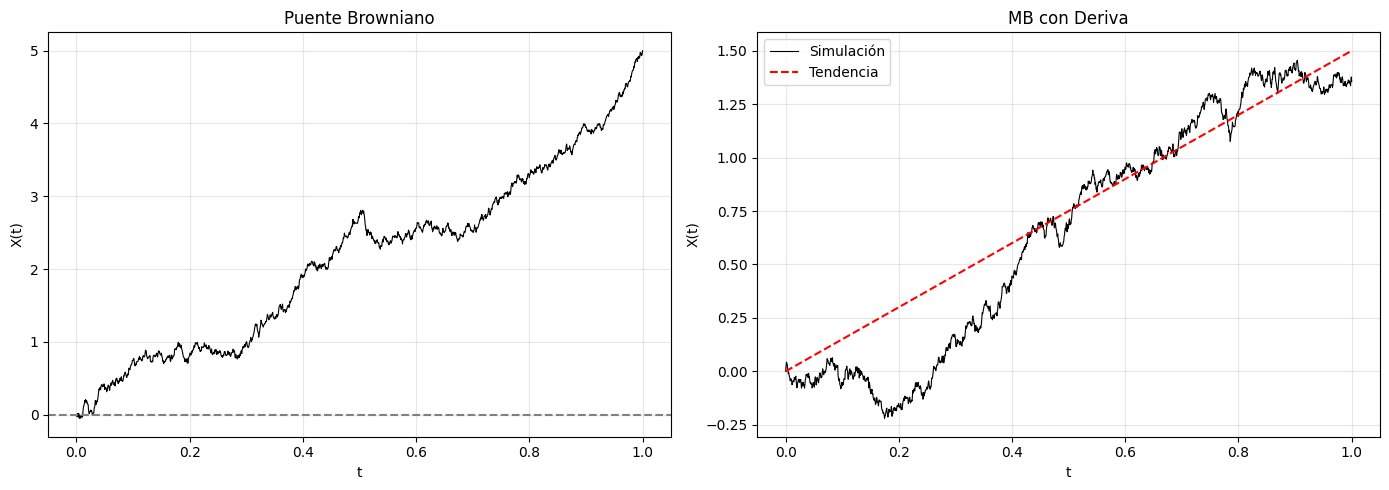

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def simular_mb_estandar(T, L):
    dt = T / L
    t = np.linspace(0, T, L + 1)
    W = np.zeros(L + 1)
    incrementos = np.random.normal(0, np.sqrt(dt), L)
    W[1:] = np.cumsum(incrementos)
    return t, W


def simular_puente_browniano(t, B_t, B1_deseado):
    T = t[-1]
    X_t = B_t - (t / T) * (B_t[-1] - B1_deseado)
    return X_t

def simular_mb_con_deriva(t, mu, sigma):
    dt = t[1] - t[0]
    L = len(t) - 1

    _, B_t = simular_mb_estandar(t[-1], L)
    X_t = mu * t + sigma * B_t
    return X_t

T = 1
L = 1500
t = np.linspace(0, T, L + 1)
np.random.seed(123)

_, B_t = simular_mb_estandar(T, L)

# Solicitar primero el valor deseado para B_1
try:
    valor_B1 = float(input("Ingresa el valor deseado para B_1: "))
except ValueError:
    print("Entrada no válida. Se usará 0 por defecto.")
    valor_B1 = 0.0

X_puente = simular_puente_browniano(t, B_t, valor_B1)
mu = 1.5
sigma = 0.5
X_deriva = simular_mb_con_deriva(t, mu, sigma)


dt = t[1] - t[0]

incrementos_deriva = np.diff(X_deriva)
mu_estimado = np.mean(incrementos_deriva) / dt
print(f"Mu teórica: {mu} | Mu estimada en simulación: {mu_estimado:.4f}")

print(f"Varianza teórica en t=1: {sigma**2 * 1}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t, X_puente, color='black', linewidth=0.8)
ax1.axhline(0, color='gray', linestyle='--')
ax1.set_title('Puente Browniano')
ax1.set_xlabel('t')
ax1.set_ylabel('X(t)')
ax1.grid(True, alpha=0.3)

# Gráfica del MB con Deriva
ax2.plot(t, X_deriva, color='black', linewidth=0.8, label='Simulación')
ax2.plot(t, mu * t, color='red', linestyle='--', label=f'Tendencia')
ax2.set_title(f'MB con Deriva')
ax2.set_xlabel('t')
ax2.set_ylabel('X(t)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()